# Artefakt-Detektor mit PyTorch (Faster R-CNN)

Feintuning eines vortrainierten Faster R-CNN (torchvision) auf dem Roboflow-COCO-Datensatz.
Vergleich **A: ohne Negativ-Bilder** vs. **B: mit Negativ-Bildern** unter identischen Bedingungen.

**Erwartete Ordnerstruktur** (relativ zum Ordner, in dem dieses Notebook liegt):
```
data/
├── processed/
│   ├── _annotations.coco.json
│   └── img_00000_png.rf....png  ...
├── negatives_train/   (Bilder ohne Artefakte, nur für Training von B)
└── negatives_test/    (andere Bilder ohne Artefakte, nur zum Testen)
```

In [9]:
# --- Setup ---------------------------------------------------------------
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'   # muss VOR dem torch-Import stehen

import json, glob, random, copy, time
import numpy as np
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.utils import draw_bounding_boxes
from PIL import Image
import matplotlib.pyplot as plt

# Pfade (relativ)
DATA_DIR      = 'data/processed'
ANN_FILE      = os.path.join(DATA_DIR, '_annotations.coco.json')
NEG_TRAIN_DIR = 'data/negatives_train'
NEG_TEST_DIR  = 'data/negatives_test'
OUT_DIR       = 'runs'

# Training
SEED       = 42
EPOCHS     = 20
BATCH      = 2        # MPS: 1-2, NVIDIA: 4
MODEL      = 'mobilenet'   # 'mobilenet' (schnell, läuft gut auf Mac) oder 'resnet50' (genauer, schwer)
IMG_SIZE   = 608           # kürzere Bildseite beim Inferenz; 480-736
LR         = 0.005
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15
CONF       = 0.5      # Konfidenz-Schwelle für Anzeige und Fehlalarm-Zählung
PRETRAINED = True     # vortrainierte COCO-Gewichte laden

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')

DEVICE = torch.device('cpu')

print('Arbeitsordner:', os.getcwd())
print('Annotations gefunden:', os.path.exists(ANN_FILE))
print('Device:', DEVICE, '| torch', torch.__version__, '| torchvision', torchvision.__version__)

Arbeitsordner: /Users/noah/Documents/Data/University/Master/Sydney/SpaceRobotics/A3
Annotations gefunden: True
Device: cpu | torch 2.8.0 | torchvision 0.23.0


## 1. COCO-Annotations laden
Doppelte Klassennamen (z. B. zweimal `stone`) werden automatisch zusammengeführt, die Roboflow-Oberkategorie wird ignoriert.

In [10]:
coco = json.load(open(ANN_FILE))

# Roboflow legt eine Oberkategorie an (z. B. 'spacerobtics') -> ignorieren
super_names = {c['supercategory'] for c in coco['categories']}
class_names = sorted({c['name'] for c in coco['categories'] if c['name'] not in super_names})
NUM_CLASSES = len(class_names)

# COCO-Kategorie-ID -> unser Label (1..K, 0 ist Hintergrund)
name_to_label = {n: i + 1 for i, n in enumerate(class_names)}
cat_to_label = {c['id']: name_to_label[c['name']]
                for c in coco['categories'] if c['name'] in name_to_label}

# Pro Bild: Pfad, Boxen (x1,y1,x2,y2), Labels
records = {img['id']: {'path': os.path.join(DATA_DIR, img['file_name']),
                       'name': img['file_name'], 'boxes': [], 'labels': []}
           for img in coco['images']}
skipped = 0
for a in coco['annotations']:
    if a['category_id'] not in cat_to_label:
        skipped += 1
        continue
    x, y, w, h = a['bbox']
    if w < 1 or h < 1:
        skipped += 1
        continue
    r = records[a['image_id']]
    r['boxes'].append([x, y, x + w, y + h])
    r['labels'].append(cat_to_label[a['category_id']])
records = list(records.values())

missing = [r['path'] for r in records if not os.path.exists(r['path'])]
print(f'{len(records)} Bilder, {NUM_CLASSES} Klassen, {skipped} Boxen übersprungen')
print(f'Fehlende Bilddateien: {len(missing)}')

counts = {n: 0 for n in class_names}
for r in records:
    for l in r['labels']:
        counts[class_names[l - 1]] += 1
for n, c in counts.items():
    print(f'  {n:<10} {c:>4} Boxen')

111 Bilder, 6 Klassen, 0 Boxen übersprungen
Fehlende Bilddateien: 0
  alien        23 Boxen
  ball         27 Boxen
  graffiti     53 Boxen
  mushroom     31 Boxen
  stone        43 Boxen
  stop         60 Boxen


## 2. Train / Val / Test aufteilen
Fester Seed, damit A und B **exakt dieselben** Val- und Test-Bilder haben.

In [11]:
rng = random.Random(SEED)
idx = list(range(len(records)))
rng.shuffle(idx)
n_test = round(len(idx) * TEST_FRAC)
n_val = round(len(idx) * VAL_FRAC)

test_records  = [records[i] for i in idx[:n_test]]
val_records   = [records[i] for i in idx[n_test:n_test + n_val]]
train_records = [records[i] for i in idx[n_test + n_val:]]

def load_negatives(folder):
    files = sorted(glob.glob(os.path.join(folder, '*.png')) + glob.glob(os.path.join(folder, '*.jpg')))
    return [{'path': f, 'name': os.path.basename(f), 'boxes': [], 'labels': []} for f in files]

neg_train = load_negatives(NEG_TRAIN_DIR)
neg_test  = load_negatives(NEG_TEST_DIR)

print(f'Train: {len(train_records)}  Val: {len(val_records)}  Test: {len(test_records)}')
print(f'Negativ-Bilder Train: {len(neg_train)}  Test: {len(neg_test)}')

Train: 77  Val: 17  Test: 17
Negativ-Bilder Train: 12  Test: 3


## 3. Dataset mit Augmentation
Nur im Training: horizontaler Flip, Helligkeit, Kontrast, Sättigung. **Kein Farbton-Shift**, weil alien und Kristall beide grün sind.
Multi-Scale-Training (verschiedene Bildgrößen) übernimmt das Modell selbst (siehe `min_size` unten).

In [12]:
class CaveDataset(Dataset):
    def __init__(self, recs, train=False):
        self.recs = recs
        self.train = train

    def __len__(self):
        return len(self.recs)

    def __getitem__(self, i):
        r = self.recs[i]
        img = Image.open(r['path']).convert('RGB')
        boxes = torch.tensor(r['boxes'], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(r['labels'], dtype=torch.int64)

        if self.train:
            if random.random() < 0.5:
                img = TF.hflip(img)
                boxes[:, [0, 2]] = img.width - boxes[:, [2, 0]]
            img = TF.adjust_brightness(img, random.uniform(0.75, 1.25))
            img = TF.adjust_contrast(img, random.uniform(0.8, 1.2))
            img = TF.adjust_saturation(img, random.uniform(0.8, 1.2))

        return TF.to_tensor(img), {'boxes': boxes, 'labels': labels}


def collate(batch):
    return tuple(zip(*batch))

## 4. Modell
Faster R-CNN, vortrainiert auf COCO. `MODEL='mobilenet'` (MobileNetV3, leicht, läuft auf Apple MPS) oder `'resnet50'` (ResNet-50-FPN v2, genauer, braucht NVIDIA-GPU).
Nur der Klassifikationskopf wird für unsere Klassen ersetzt. Kleinere Anker (ab 16 px), weil viele Artefakte sehr klein sind.

In [13]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator


def build_model(num_classes):
    if MODEL == 'resnet50':
        sizes = tuple(s for s in (IMG_SIZE - 128, IMG_SIZE - 64, IMG_SIZE) if s > 0)
        model = fasterrcnn_resnet50_fpn_v2(
            weights='DEFAULT' if PRETRAINED else None, weights_backbone=None,
            min_size=sizes, max_size=int(IMG_SIZE * 1.5))
        # kleinere Anker (ab 16 px) für die vielen winzigen Artefakte
        model.rpn.anchor_generator = AnchorGenerator(
            sizes=((16,), (32,), (64,), (128,), (256,)), aspect_ratios=((0.5, 1.0, 2.0),) * 5)
    else:
        model = fasterrcnn_mobilenet_v3_large_fpn(
            weights='DEFAULT' if PRETRAINED else None, weights_backbone=None,
            min_size=IMG_SIZE, max_size=int(IMG_SIZE * 1.5))
        # kleinere Anker, gleiche Anzahl pro Position -> vortrainierte Gewichte passen weiter
        model.rpn.anchor_generator = AnchorGenerator(
            sizes=((16, 32, 64, 128, 256),) * 3, aspect_ratios=((0.5, 1.0, 2.0),) * 3)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)  # +1 Hintergrund
    return model

## 5. Auswertung
- **mAP** über `torchmetrics`
- **Fehlalarme** auf Bildern ohne Artefakte (hier zeigt sich der Effekt der Negativ-Bilder)

In [ ]:
from torchmetrics.detection import MeanAveragePrecision


@torch.no_grad()
def predict(model, img_tensor):
    model.eval()
    out = model([img_tensor.to(DEVICE)])[0]
    return {k: v.cpu() for k, v in out.items()}


def evaluate(model, recs, iou_thresholds=None, class_metrics=False):
    metric = MeanAveragePrecision(iou_type='bbox', iou_thresholds=iou_thresholds,
                                  class_metrics=class_metrics)
    ds = CaveDataset(recs)
    for i in range(len(ds)):
        img, t = ds[i]
        p = predict(model, img)
        metric.update([p], [t])
    return metric.compute()


def count_false_alarms(model, neg_recs, conf=CONF):
    ds = CaveDataset(neg_recs)
    boxes, images = 0, 0
    for i in range(len(ds)):
        img, _ = ds[i]
        n = int((predict(model, img)['scores'] >= conf).sum())
        boxes += n
        images += n > 0
    return images, boxes

## 6. Trainingsschleife

In [15]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)


def train_model(train_recs, run_name):
    set_seed(SEED)
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = build_model(NUM_CLASSES).to(DEVICE)
    loader = DataLoader(CaveDataset(train_recs, train=True), batch_size=BATCH,
                        shuffle=True, collate_fn=collate, num_workers=0)

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    warmup_iters = min(100, len(loader))

    history, best_map, it = [], -1.0, 0
    for ep in range(1, EPOCHS + 1):
        model.train()
        t0, ep_loss = time.time(), 0.0
        for imgs, tgts in loader:
            if ep == 1 and it < warmup_iters:          # sanfter Start
                for g in opt.param_groups:
                    g['lr'] = LR * (it + 1) / warmup_iters
            imgs = [im.to(DEVICE) for im in imgs]
            tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
            loss = sum(model(imgs, tgts).values())
            opt.zero_grad()
            loss.backward()
            opt.step()
            ep_loss += loss.item()
            it += 1
            if DEVICE.type == 'mps':
                torch.mps.empty_cache()
        sched.step()

        m = evaluate(model, val_records)
        row = {'epoch': ep, 'loss': ep_loss / len(loader),
               'val_map50': m['map_50'].item(), 'val_map': m['map'].item()}
        history.append(row)
        flag = ''
        if row['val_map50'] > best_map:
            best_map = row['val_map50']
            torch.save(model.state_dict(), os.path.join(run_dir, 'best.pt'))
            flag = '  <- bestes Modell gespeichert'
        print(f"[{run_name}] Epoche {ep:>2}/{EPOCHS}  loss={row['loss']:.3f}  "
              f"val mAP50={row['val_map50']:.3f}  ({time.time() - t0:.0f}s){flag}")

    json.dump({'class_names': class_names, 'history': history},
              open(os.path.join(run_dir, 'info.json'), 'w'), indent=2)
    model.load_state_dict(torch.load(os.path.join(run_dir, 'best.pt'), map_location=DEVICE))
    return model, history

## 7. Modell A trainieren (ohne Negativ-Bilder)

In [16]:
model_A, hist_A = train_model(train_records, 'A_no_neg')

[A_no_neg] Epoche  1/20  loss=0.525  val mAP50=0.085  (76s)  <- bestes Modell gespeichert
[A_no_neg] Epoche  2/20  loss=0.642  val mAP50=0.652  (66s)  <- bestes Modell gespeichert
[A_no_neg] Epoche  3/20  loss=0.695  val mAP50=0.729  (63s)  <- bestes Modell gespeichert
[A_no_neg] Epoche  4/20  loss=0.611  val mAP50=0.866  (61s)  <- bestes Modell gespeichert
[A_no_neg] Epoche  5/20  loss=0.675  val mAP50=0.826  (60s)
[A_no_neg] Epoche  6/20  loss=0.540  val mAP50=0.892  (62s)  <- bestes Modell gespeichert
[A_no_neg] Epoche  7/20  loss=0.648  val mAP50=0.857  (61s)
[A_no_neg] Epoche  8/20  loss=0.597  val mAP50=0.937  (64s)  <- bestes Modell gespeichert
[A_no_neg] Epoche  9/20  loss=0.564  val mAP50=0.923  (59s)
[A_no_neg] Epoche 10/20  loss=0.560  val mAP50=0.909  (61s)
[A_no_neg] Epoche 11/20  loss=0.552  val mAP50=0.869  (59s)
[A_no_neg] Epoche 12/20  loss=0.526  val mAP50=0.908  (70s)
[A_no_neg] Epoche 13/20  loss=0.425  val mAP50=0.900  (61s)
[A_no_neg] Epoche 14/20  loss=0.405  val

## 8. Modell B trainieren (mit Negativ-Bildern)
Gleiche Einstellungen, gleicher Seed, nur zusätzlich die Negativ-Bilder im Training.

In [17]:
if not neg_train:
    print(f'Keine Negativ-Bilder in {NEG_TRAIN_DIR} gefunden -> Modell B wird übersprungen.')
    model_B, hist_B = None, None
else:
    model_B, hist_B = train_model(train_records + neg_train, 'B_with_neg')

[B_with_neg] Epoche  1/20  loss=0.479  val mAP50=0.146  (82s)  <- bestes Modell gespeichert
[B_with_neg] Epoche  2/20  loss=0.558  val mAP50=0.760  (72s)  <- bestes Modell gespeichert
[B_with_neg] Epoche  3/20  loss=0.680  val mAP50=0.676  (70s)
[B_with_neg] Epoche  4/20  loss=0.589  val mAP50=0.806  (68s)  <- bestes Modell gespeichert
[B_with_neg] Epoche  5/20  loss=nan  val mAP50=0.917  (72s)  <- bestes Modell gespeichert
[B_with_neg] Epoche  6/20  loss=0.605  val mAP50=0.868  (69s)
[B_with_neg] Epoche  7/20  loss=0.554  val mAP50=0.907  (72s)
[B_with_neg] Epoche  8/20  loss=0.557  val mAP50=0.921  (67s)  <- bestes Modell gespeichert
[B_with_neg] Epoche  9/20  loss=0.527  val mAP50=0.894  (71s)
[B_with_neg] Epoche 10/20  loss=0.482  val mAP50=0.937  (74s)  <- bestes Modell gespeichert
[B_with_neg] Epoche 11/20  loss=0.486  val mAP50=0.930  (74s)
[B_with_neg] Epoche 12/20  loss=0.454  val mAP50=0.935  (71s)
[B_with_neg] Epoche 13/20  loss=nan  val mAP50=0.925  (71s)
[B_with_neg] Epoch

## 9. Vergleich auf dem Testset

In [18]:
models = {'A ohne Neg': model_A}
if model_B is not None:
    models['B mit Neg'] = model_B

print(f"{'Modell':<12}{'mAP50':>8}{'mAP50-95':>10}{'Recall':>8}{'Fehlalarm-Bilder':>18}{'falsche Boxen':>15}")
summary = {}
for tag, m in models.items():
    r = evaluate(m, test_records)
    fa_img, fa_box = count_false_alarms(m, neg_test) if neg_test else (float('nan'), float('nan'))
    summary[tag] = r
    fa_txt = f'{fa_img}/{len(neg_test)}' if neg_test else '-'
    print(f"{tag:<12}{r['map_50'].item():>8.3f}{r['map'].item():>10.3f}"
          f"{r['mar_100'].item():>8.3f}{fa_txt:>18}{str(fa_box) if neg_test else '-':>15}")

Modell         mAP50  mAP50-95  Recall  Fehlalarm-Bilder  falsche Boxen
A ohne Neg     0.974     0.618   0.652               0/3              0
B mit Neg      0.949     0.584   0.625               0/3              0


### mAP50 pro Klasse

In [19]:
per_class = {tag: evaluate(m, test_records, iou_thresholds=[0.5], class_metrics=True)
             for tag, m in models.items()}

print(f"{'Klasse':<12}" + ''.join(f'{t:>14}' for t in models))
for lbl, name in enumerate(class_names, start=1):
    row = f'{name:<12}'
    for tag in models:
        r = per_class[tag]
        cls = r['classes'].tolist()
        cls = cls if isinstance(cls, list) else [cls]
        vals = r['map_per_class'].flatten().tolist()
        v = vals[cls.index(lbl)] if lbl in cls else float('nan')
        row += f'{v:>14.3f}' if v >= 0 else f"{'n/a':>14}"
    print(row)

Klasse          A ohne Neg     B mit Neg
alien                1.000         1.000
ball                 1.000         1.000
graffiti             0.941         0.845
mushroom             1.000         1.000
stone                1.000         1.000
stop                 0.901         0.851


### Trainingskurven

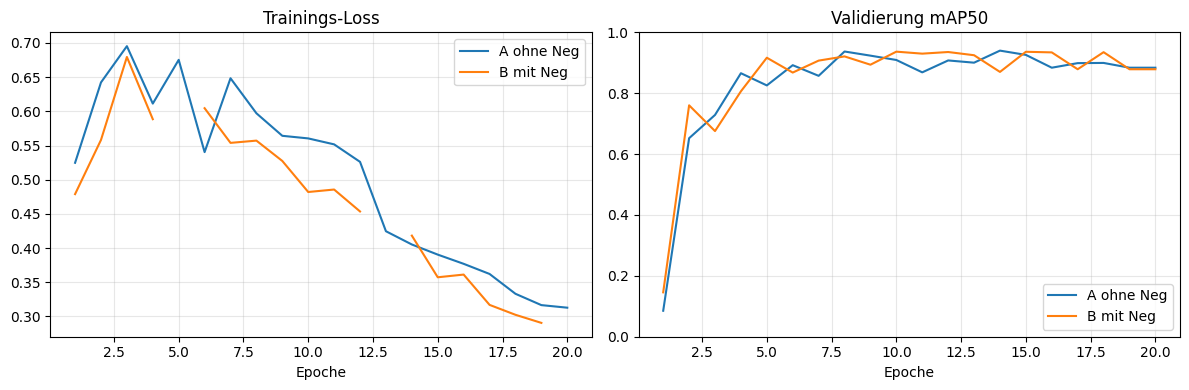

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for tag, h in [('A ohne Neg', hist_A), ('B mit Neg', hist_B)]:
    if h is None:
        continue
    ep = [r['epoch'] for r in h]
    axes[0].plot(ep, [r['loss'] for r in h], label=tag)
    axes[1].plot(ep, [r['val_map50'] for r in h], label=tag)
axes[0].set(title='Trainings-Loss', xlabel='Epoche')
axes[1].set(title='Validierung mAP50', xlabel='Epoche', ylim=(0, 1))
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'training_curves.png'), dpi=150)
plt.show()

## 10. Visueller Vergleich
Einige Test-Bilder und Negativ-Bilder, links A, rechts B.

/Users/noah/Library/Python/3.9/lib/python/site-packages/torchvision/utils.py:349: UserWarning: boxes doesn't contain any box. No box was drawn
  warnings.warn("boxes doesn't contain any box. No box was drawn")


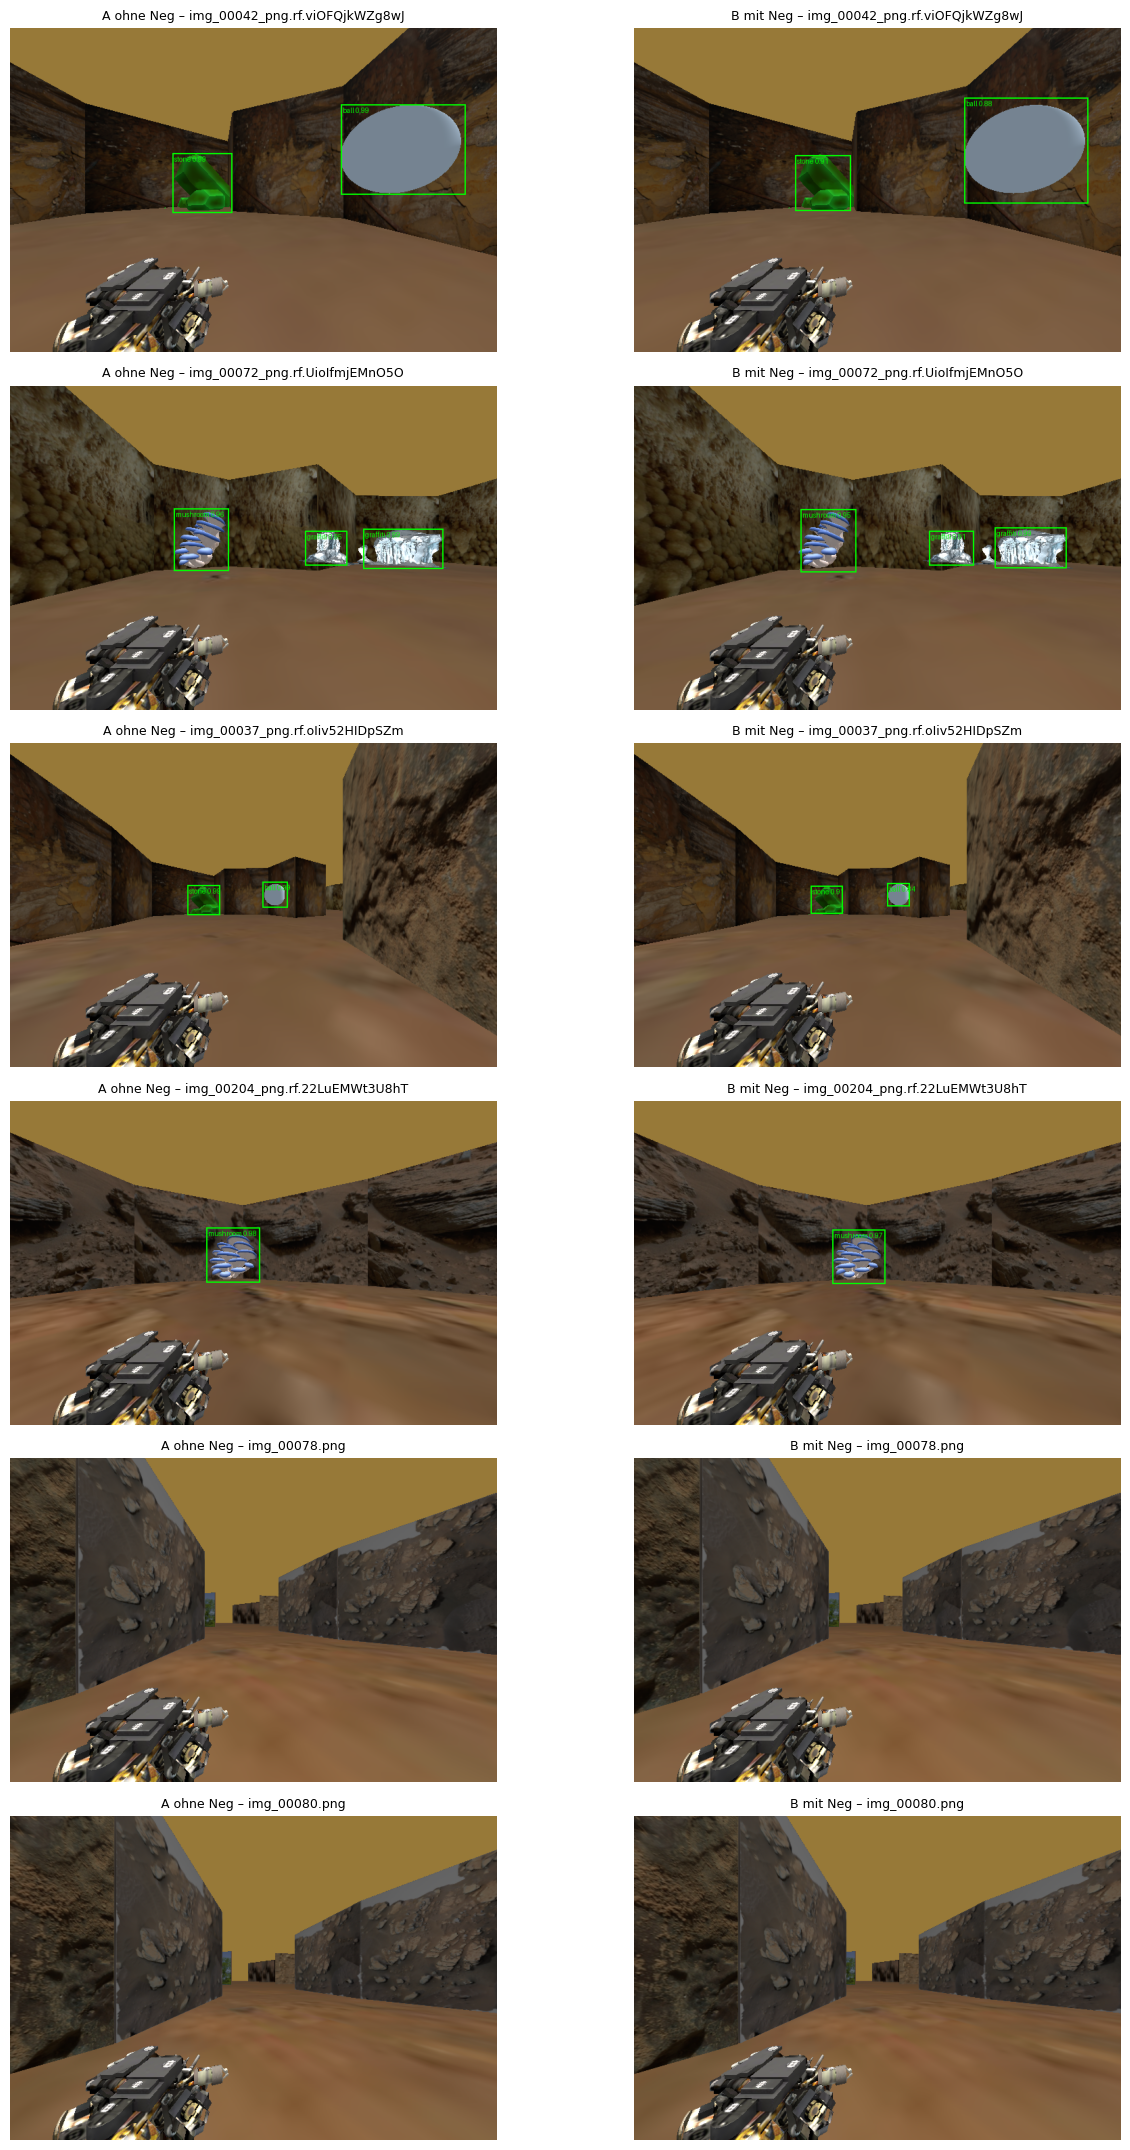

In [21]:
def draw(model, rec, conf=CONF):
    img, _ = CaveDataset([rec])[0]
    p = predict(model, img)
    keep = p['scores'] >= conf
    labels = [f"{class_names[l - 1]} {s:.2f}" for l, s in zip(p['labels'][keep], p['scores'][keep])]
    img_u8 = (img * 255).to(torch.uint8)
    out = draw_bounding_boxes(img_u8, p['boxes'][keep], labels=labels, colors='lime', width=2)
    return out.permute(1, 2, 0).numpy()

random.seed(0)
samples = random.sample(test_records, min(4, len(test_records))) + neg_test[:2]
cols = list(models.items())
fig, axes = plt.subplots(len(samples), len(cols), figsize=(7 * len(cols), 3.6 * len(samples)), squeeze=False)
for row, rec in zip(axes, samples):
    for ax, (tag, m) in zip(row, cols):
        ax.imshow(draw(m, rec))
        ax.set_title(f'{tag} – {rec["name"][:30]}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'comparison.png'), dpi=120)
plt.show()

## 11. Modell später in ROS laden
Gespeichert sind `runs/<name>/best.pt` (Gewichte) und `runs/<name>/info.json` (Klassennamen).
In `cave_explorer.py` reicht dann:
```python
model = build_model(num_classes)          # gleiche Funktion wie oben, PRETRAINED egal
model.load_state_dict(torch.load('best.pt', map_location='cpu'))
model.eval()
```